# Forecasting monthly CO₂ with Gaussian process regression

This adaptation of the [pinned scikit-learn gallery example](https://github.com/scikit-learn/scikit-learn/blob/4358542a1bd39af2e7e1cbace8b9fed067473c5b/examples/gaussian_process/plot_gpr_co2.py) uses a seeded synthetic series that runs offline. The synthetic concentrations mimic a rising trend, annual seasonality and shorter fluctuations. The final two years are held out, so the forecast can be compared with observations beyond the fitting period.

The scikit-learn developers released the gallery source under BSD-3-Clause. See the [family license notices](../../LICENSES/gaussian-process-NOTICES).

In [1]:
import runpy
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("gaussian_process/plot_gpr_co2")

reference = runpy.run_path(str(ROOT / "tests/gaussian_process/regression/parity.py"))
Regressor, kernels = reference["GPR"], reference["K"]

## Generate monthly concentrations and hold out the last two years

Time is measured in years since the first observation, so a period of one represents an annual cycle. We subtract the training mean and leave the targets in ppm. This keeps the kernel amplitudes interpretable in ppm and uses only training observations to center the fit.

In [2]:
rng = np.random.default_rng(15)
X = (np.arange(168) / 12).reshape(-1, 1)
years = X[:, 0]
distance = np.abs(years[:, None] - years)
noise_covariance = 0.12**2 * np.exp(-0.5 * (distance / 0.13)**2)
correlated_noise = np.linalg.cholesky(noise_covariance) @ rng.standard_normal(len(X))
y = (325 + 1.4 * years + 0.02 * years**2
     + (2.0 + 0.035 * years) * np.sin(2 * np.pi * years)
     + 0.35 * np.cos(4 * np.pi * years)
     + 0.3 * np.sin(2 * np.pi * years / 3.5)
     + correlated_noise + 0.08 * rng.standard_normal(len(X)))
n_train = 144
X_train = X[:n_train]
training_mean = y[:n_train].mean()
y_centered = y[:n_train] - training_mean
queries_per_month = 3
query_count = queries_per_month * (len(X) - 1) + 1
X_query = (np.arange(query_count) / (12 * queries_per_month)).reshape(-1, 1)
nb.share(X_train=X_train, y_centered=y_centered, X_query=X_query)

## Combine trend, seasonality, irregular variation and noise

A smooth RBF models the long-term trend. A second RBF controls how quickly the seasonal covariance decays, while the exponential sine squared kernel fixes the seasonal period at one year. A rational quadratic term captures fluctuations across several timescales. A short-scale RBF models correlated noise, and a white kernel models independent observation noise.

Both implementations optimize log marginal likelihood from the same initial kernel. The synthetic series is shorter than the gallery dataset, so bounded search assigns the smooth and short-scale components distinct ranges and fixes the rational quadratic's scale-mixture parameter.

In [3]:
trend = kernels.ConstantKernel(100.0, (5.0, 1e4)) * kernels.RBF(15.0, (5.0, 60.0))
seasonal = (
    kernels.ConstantKernel(4.0, (0.1, 20.0)) * kernels.RBF(12.0, (3.0, 40.0))
    * kernels.ExpSineSquared(1.0, 1.0, (0.3, 3.0), "fixed")
)
irregular = kernels.ConstantKernel(0.15, (0.005, 2.0)) * kernels.RationalQuadratic(
    length_scale=0.8, alpha=1.0, length_scale_bounds=(0.3, 2.0), alpha_bounds="fixed",
)
noise = (
    kernels.ConstantKernel(0.02, (0.001, 0.2)) * kernels.RBF(0.15, (0.07, 0.25))
    + kernels.WhiteKernel(0.006, (0.0005, 0.05))
)
model = Regressor(kernel=trend + seasonal + irregular + noise).fit(X_train, y_centered)
mean, std = model.predict(X_query, return_std=True)
oracle = dict(
    mean=mean + training_mean,
    std=std,
    theta=model.kernel_.theta,
    lml=np.array([model.log_marginal_likelihood_value_]),
)
print(model.kernel_)

29.9**2 * RBF(length_scale=27.9) + 3.61**2 * RBF(length_scale=40) * ExpSineSquared(length_scale=3, periodicity=1) + 0.628**2 * RationalQuadratic(alpha=1, length_scale=1.31) + 0.141**2 * RBF(length_scale=0.11) + WhiteKernel(noise_level=0.00378)


/home/strgenix/postdoc/projects/mojods/porting-sklearn/scikit-learn/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__k2__k1__k2__length_scale is close to the specified upper bound 40.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/strgenix/postdoc/projects/mojods/porting-sklearn/scikit-learn/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__k2__k2__length_scale is close to the specified upper bound 3.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


In [4]:
%%mojo co2_forecast
from moxie.gaussian_process import GaussianProcessRegressor
from moxie.gaussian_process.kernels import (
    Bounds, ConstantKernel, ExpSineSquared, RBF, RationalQuadratic, WhiteKernel,
)
from moxie_nb_io import load, save, save_floats


def main() raises:
    var trend = ConstantKernel(100.0, Bounds(5.0, 1e4)) * RBF(15.0, Bounds(5.0, 60.0))
    var seasonal = (
        ConstantKernel(4.0, Bounds(0.1, 20.0)) * RBF(12.0, Bounds(3.0, 40.0))
        * ExpSineSquared(1.0, 1.0, Bounds(0.3, 3.0), Bounds.fixed())
    )
    var irregular = ConstantKernel(0.15, Bounds(0.005, 2.0)) * RationalQuadratic(
        length_scale=0.8, alpha=1.0, length_scale_bounds=Bounds(0.3, 2.0),
        alpha_bounds=Bounds.fixed(),
    )
    var noise = (
        ConstantKernel(0.02, Bounds(0.001, 0.2)) * RBF(0.15, Bounds(0.07, 0.25))
        + WhiteKernel(0.006, Bounds(0.0005, 0.05))
    )
    var model = GaussianProcessRegressor(trend + seasonal + irregular + noise)
    _ = model.fit(load("X_train"), load("y_centered"))
    # Restore the ppm offset in the comparison cell for both models.
    var prediction = model.predict(load("X_query"), return_std=True)
    save("mean", prediction.mean)
    save("std", prediction.std.value())
    save("theta", model.kernel_.theta())
    save_floats("lml", [model.log_marginal_likelihood_value_])
    print(model.kernel_)

29.9**2 * RBF(length_scale=27.9) + 3.61**2 * RBF(length_scale=40) * ExpSineSquared(length_scale=3, periodicity=1) + 0.628**2 * RationalQuadratic(alpha=1, length_scale=1.31) + 0.141**2 * RBF(length_scale=0.11) + WhiteKernel(noise_level=0.00378)


## Compare the fitted models and their forecasts

The shaded band spans one posterior standard deviation, as in the gallery. It includes the contribution of the white kernel to future observations. The vertical line marks the first held-out month.

Both fits reach the upper bounds for the seasonal decay and smoothness length scales. Their warnings identify the limits of the search on this series. The forecast comparison checks agreement at those fitted values.

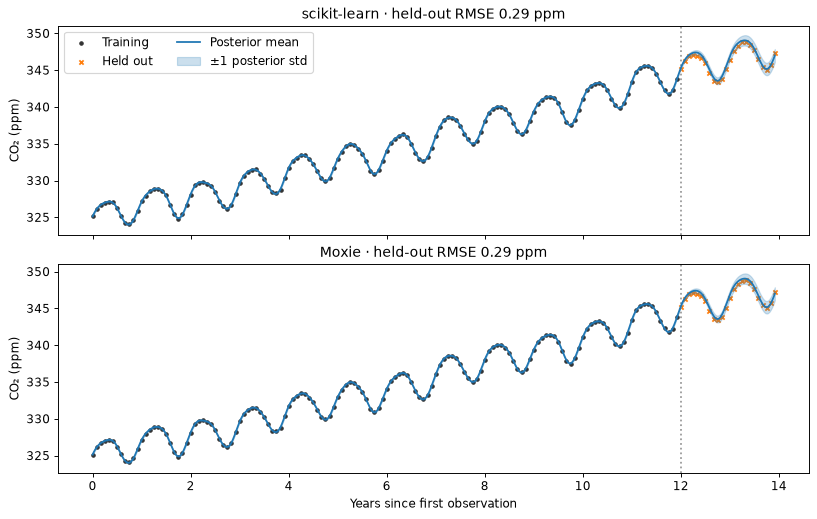

In [5]:
result = nb.results["co2_forecast"]
native = dict(result, mean=result["mean"] + training_mean)
fig, axes = plt.subplots(2, 1, figsize=(9.5, 6), dpi=85, sharex=True, sharey=True,
                         layout="constrained")
for ax, (title, forecast) in zip(axes, (("scikit-learn", oracle), ("Moxie", native))):
    ax.scatter(years[:n_train], y[:n_train], s=8, color="0.2", label="Training")
    ax.scatter(years[n_train:], y[n_train:], s=13, marker="x", color="tab:orange",
               label="Held out")
    ax.axvline(years[n_train], color="0.6", linestyle=":")
    ax.plot(X_query[:, 0], forecast["mean"], color="tab:blue", label="Posterior mean")
    ax.fill_between(X_query[:, 0], forecast["mean"] - forecast["std"],
                    forecast["mean"] + forecast["std"], alpha=0.23, color="tab:blue",
                    label="±1 posterior std")
    monthly_mean = forecast["mean"][::queries_per_month]
    rmse = np.sqrt(np.mean((monthly_mean[n_train:] - y[n_train:])**2))
    ax.set(title=f"{title} · held-out RMSE {rmse:.2f} ppm", ylabel="CO₂ (ppm)")
axes[0].legend(loc="upper left", ncols=2)
axes[1].set_xlabel("Years since first observation")
plt.show()

In [6]:
# Absolute tolerances keep the concentration offset from masking forecast errors.
for label, key in (("Posterior mean (ppm)", "mean"), ("Posterior std (ppm)", "std")):
    nb.compare(label, oracle[key], native[key], rtol=0, atol=1e-5,
               reason="Agreement well below the simulated 0.08 ppm observation noise.")
nb.compare("Fitted log hyperparameters", oracle["theta"], native["theta"], rtol=0, atol=1e-4,
           reason="Allows small differences from independent optimizer stopping.")
nb.compare("Log marginal likelihood", oracle["lml"], native["lml"], rtol=0, atol=1e-6,
           reason="Allows Float64 accumulation differences across factorizations.")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
Posterior mean (ppm),PASS,"(502,)","(502,)",7.86e-10,2.27e-12,"rtol=0, atol=1e-05",,Agreement well below the simulated 0.08 ppm observation noise.
Posterior std (ppm),PASS,"(502,)","(502,)",1.96e-10,4.63e-10,"rtol=0, atol=1e-05",,Agreement well below the simulated 0.08 ppm observation noise.
Fitted log hyperparameters,PASS,"(10,)","(10,)",7.54e-09,1.11e-09,"rtol=0, atol=0.0001",,Allows small differences from independent optimizer stopping.
Log marginal likelihood,PASS,"(1,)","(1,)",2.79e-10,4.73e-12,"rtol=0, atol=1e-06",,Allows Float64 accumulation differences across factorizations.
